In [1]:
library(tidyverse)
library(fs)
library(ggtext)
library(systemfonts)

ws = '/root/prompt-injection-as-role-confusion'

source(paste0(ws, '/r-utils/plots.r'))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.4.4     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
model_prefixes = c('gptoss-20b')

# Probe training accuracy

In [3]:
acc_by_role = list_rbind(map(model_prefixes, function(model_prefix)
  read_csv(file.path(ws, str_glue('experiments/role-analysis/outputs/probe-training/acc_by_role_{model_prefix}.csv')))
))

median_layers =
  acc_by_role %>%
  distinct(., model, layer_ix) %>%
  group_by(., model) %>%
  summarise(layer_ix = sort(layer_ix)[floor(n()/2) + 2])

acc_by_role

Rows: 1237 Columns: 6


── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): role, pred, model, role_space
dbl (2): count, layer_ix



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


role,pred,count,model,layer_ix,role_space
<chr>,<chr>,<dbl>,<chr>,<dbl>,<chr>
assistant,assistant,6760,gptoss-20b,0,"user,assistant"
assistant,user,8842,gptoss-20b,0,"user,assistant"
user,assistant,6363,gptoss-20b,0,"user,assistant"
user,user,6823,gptoss-20b,0,"user,assistant"
assistant,assistant,10322,gptoss-20b,2,"user,assistant"
assistant,user,5280,gptoss-20b,2,"user,assistant"
user,assistant,3485,gptoss-20b,2,"user,assistant"
user,user,9701,gptoss-20b,2,"user,assistant"
assistant,assistant,9604,gptoss-20b,4,"user,assistant"


In [4]:
# Highest accuracy training layer
acc_by_role %>%
  filter(role_space == 'user,assistant,tool') %>%
  mutate(., is_correct = ifelse(role == pred, 1, 0)) %>%
  group_by(model, role, layer_ix, is_correct) %>%
  summarize(., count = sum(count), .groups = 'drop') %>%
  group_by(., model, layer_ix) %>%
  summarize(., accuracy = sum(is_correct * count)/sum(count), .groups = 'drop') %>%
  group_by(., model) %>%
  slice_max(accuracy, n = 1)

model,layer_ix,accuracy
<chr>,<dbl>,<dbl>
gptoss-20b,16,0.921759


# Accuracy on conversational data

In [5]:
model_prefixes = c('gptoss-20b')
include_old_variant = F

base_acc = list_rbind(map(model_prefixes, function(model_prefix)
  read_csv(file.path(ws, str_glue('experiments/role-analysis/outputs/probe-projections/all_conv_acc_{model_prefix}.csv'))) %>%
    mutate(., model = model_prefix)
))

alt_acc = base_acc[0,]
message('Cross-model comparison skipped by user instruction.')

projections = bind_rows(base_acc, alt_acc)

projections

Rows: 960 Columns: 5


── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): conv_type, role_space, role
dbl (2): layer_ix, mean_acc



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Cross-model comparison skipped by user instruction.



conv_type,role_space,layer_ix,role,mean_acc,model
<chr>,<chr>,<dbl>,<chr>,<dbl>,<chr>
tagged,ua,0,assistant,0.4980919,gptoss-20b
tagged,ua,0,user,0.8387104,gptoss-20b
tool_tagged,ua,0,assistant,0.3974442,gptoss-20b
tool_tagged,ua,0,user,0.1906539,gptoss-20b
untagged,ua,0,assistant,0.3961360,gptoss-20b
untagged,ua,0,user,0.7200444,gptoss-20b
user_tagged,ua,0,assistant,0.3973048,gptoss-20b
user_tagged,ua,0,user,0.8336454,gptoss-20b
tagged,ua,2,assistant,0.9914152,gptoss-20b


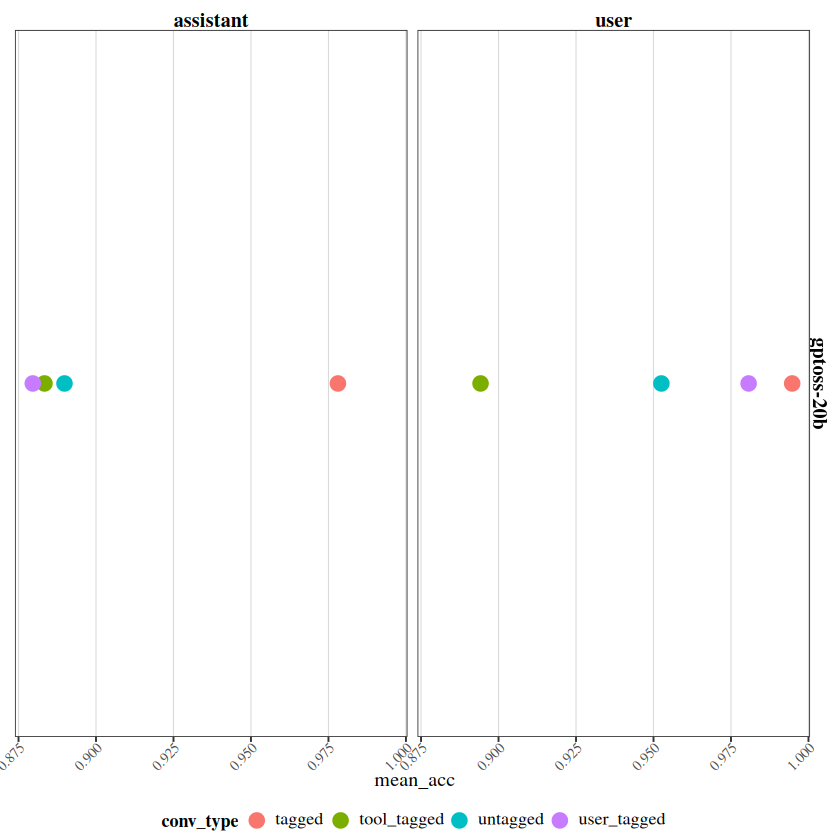

In [6]:
# Get mid-layer results only

convs_df = 
  projections %>%
  filter(., role_space == 'uat') %>%
  inner_join(median_layers, join_by(model, layer_ix)) %>%
  select(., -role_space, -layer_ix) %>%
  mutate(., conv_type_2 = case_when(
    role == 'user' & conv_type == 'tagged' ~ 'user_in_user_role_tags',
    role == 'assistant' & conv_type == 'tagged' ~ 'asst_in_asst_role_tags',

    role == 'user' & conv_type == 'untagged' ~ 'user_no_role_tags',
    role == 'assistant' & conv_type == 'untagged' ~ 'assistant_no_role_tags',

    role == 'user' & conv_type == 'tool_tagged' ~ 'user_tool_tagged',
    role == 'assistant' & conv_type == 'tool_tagged' ~ 'assistant_tool_tagged',

    role == 'assistant' & conv_type == 'user_tagged' ~ 'assistant_user_tagged'
  ))
  
convs_df %>%
  filter(., !is.na(conv_type)) %>%
  mutate(., y = 0) %>%
  ggplot() +
  geom_point(aes(x = mean_acc, y = y, color = conv_type), size = 4) +
  facet_grid(rows = vars(model), cols = vars(role)) +
  theme_iclr(base_size = 12) +
  theme(
    axis.text.y = element_blank(),
    axis.ticks.y = element_blank(),
    axis.title.y = element_blank(),
    panel.grid.major.y = element_blank(),
    panel.grid.minor.y = element_blank()
  ) 

# convs_df %>%
#   write_csv(file.path(ws, 'experiments/role-analysis/outputs/summary-stats/convs_results.csv'))
write_csv(convs_df,file.path(ws,'experiments/role-analysis/outputs/local-gptoss20b/r-midlayer-validation.csv'))
ggsave(str_glue('{ws}/experiments/role-analysis/outputs/local-gptoss20b/plots/midlayer-validation.png'),plot=last_plot(),width=7,height=3.5,dpi=300)
ggsave(str_glue('{ws}/experiments/role-analysis/outputs/local-gptoss20b/plots/midlayer-validation.pdf'),plot=last_plot(),width=7,height=3.5,device=cairo_pdf)


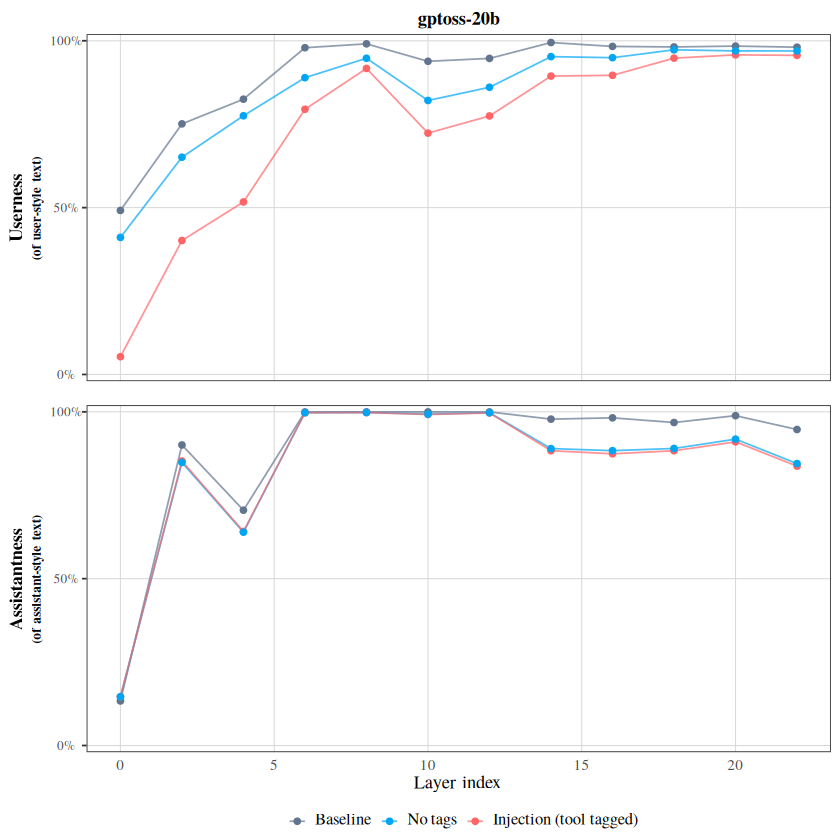

In [7]:
plot =
  projections %>%
  filter(., role_space == 'uat') %>%
  filter(., conv_type %in% c('tagged', 'untagged', 'tool_tagged')) %>%
  mutate(
    .,
    model = factor(
        model,
        levels = c('gptoss-20b', 'gptoss-120b', 'nemotron-3-nano', 'qwen3-30b-a3b'),
        labels = c('gptoss-20b', 'gptoss-120b', 'nemotron-3-nano', 'qwen3-30b-a3b')
    ),
    conv_type = factor(
        conv_type,
        levels = c('tagged', 'untagged', 'tool_tagged'),
        labels = c('Baseline', 'No tags', 'Injection (tool tagged)')
    ),
    role = factor(
        role,
        levels = c('user', 'assistant'),
        labels = c(
          'Userness<br><span style="font-size:8pt; font-weight:normal">(of user-style text)</span>',
          'Assistantness<br><span style="font-size:8pt; font-weight:normal">(of assistant-style text)</span>'
        )
    )
  ) %>%
  ggplot() +
  geom_line(aes(x = layer_ix, y = mean_acc, color = conv_type), linewidth = 0.5, alpha = 0.7) +
  geom_point(aes(x = layer_ix, y = mean_acc, color = conv_type), size = 1.5) +
  scale_color_manual(
    values = c(
      'Baseline' = '#62748e',
      'No tags' = '#00a6f4',
      'Injection (tool tagged)' = '#ff6467'
    ),
    name = NULL
  ) +
  facet_grid(cols = vars(model), rows = vars(role), scales = 'free', switch = 'y') +
  scale_y_continuous(
      labels = scales::percent_format(accuracy = 1),
      limits = c(0, 1),
      expand = expansion(mult = c(0.02, 0.02)),
      breaks = c(0, 0.5, 1)
  ) +
  labs(
    x = 'Layer index',  y = NULL
  ) +
  theme_iclr(base_size = 11) +
  theme(
      plot.title = ggtext::element_markdown(size = 11),
      axis.title.y = ggtext::element_markdown(angle = 90, vjust = 0.5, margin = margin(r = 6)),
      strip.placement = 'outside',
      panel.spacing.y = unit(1.0, "lines"),
      axis.text.x = ggtext::element_markdown(size = 9, hjust = 0.5, angle = 0, margin = margin(t = 2)),
      axis.line.x = element_blank(),
      axis.ticks.x = element_blank(),
      strip.text.x = element_text(margin = margin(b = 4)),
      strip.text.y.left = ggtext::element_markdown(angle = 90, face = 'bold')
      # panel.grid.major.x = element_blank(),
      # panel.grid.minor.x = element_blank(),
  )

# ggsave(
#     str_glue('{ws}/experiments/role-analysis/plots/cross-model-validation.pdf'),
#     plot = plot, width = 7, height = 3.5, units = 'in', dpi = 300, device = cairo_pdf
# )
# ggsave(
#     str_glue('{ws}/experiments/role-analysis/plots/cross-model-validation.png'),
#     plot = plot,  width = 7, height = 3.5, units = 'in', dpi = 300
# )

# ggsave(
#     str_glue('{ws}/docs/cross-model-validation.png'),
#     plot = plot, width = 7, height = 3.5, units = 'in', dpi = 300
# )

plot
ggsave(str_glue('{ws}/experiments/role-analysis/outputs/local-gptoss20b/plots/conversation-validation.png'),plot=plot,width=7,height=3.5,dpi=300)
ggsave(str_glue('{ws}/experiments/role-analysis/outputs/local-gptoss20b/plots/conversation-validation.pdf'),plot=plot,width=7,height=3.5,device=cairo_pdf)

writeLines(capture.output(sessionInfo()),file.path(ws,'experiments/role-analysis/outputs/local-gptoss20b/R-sessionInfo.txt'))
